# Global registration across very different fields of view: a feasibility test

**Question.** Can a coarse global registration find a small EM volume (e.g. 10 µm across) inside a large FM volume (e.g. 200 µm across), *including its orientation*? If so, it would also remove the manual "nearest orthogonal orientation" step that point cloud registration needs today ([#73](https://github.com/martlj/napari-clemreg/issues/73)).

**Approach.** Everything here is synthetic, so the true transform is known:

1. Simulate a 200 µm FM field of cells with mitochondria, segment it the way FM looks (blurred, anisotropic, thresholded) and sample points the way clemreg does (2D Canny per z slice).
2. Cut EM volumes of several sizes out of the same ground truth at EM resolution, with a random rotation and a random z flip.
3. Register each EM cloud back into the FM cloud with several coarse methods, refine every result locally with ICP, and score it against the truth.

**Methods compared** (coarse step; every one is followed by the same local ICP refinement):

| Method | Needs a rough position? | Handles any 3D rotation? |
|---|---|---|
| RANSAC on FPFH features (open3d) | no | yes |
| RANSAC on FPFH features, FM cropped around a rough position | yes | yes |
| FFT template matching over in-plane rotations | no | no: in-plane rotation, flip, small tilt only |
| FFT template matching, peak searched near a rough position | yes | no |
| Multi-start rigid CPD (the #73 multi-start idea), FM cropped around a rough position | yes | yes, from orthogonal starts |
| TEASER++ on FPFH correspondences (optional, if installed) | no | yes |

A "rough position" stands for what a user usually knows from correlative navigation (finder grid, branding marks): one click in napari, here simulated as the true EM centre plus a random error of up to `PRIOR_ERROR_UM`.

**Three rotation scenarios:**

- `planar`: EM and FM share roughly the same z axis (any in-plane rotation, a tilt of up to 5° and a 50% chance of a z flip). Typical for serial sections or a block imaged face-on.
- `rotated`: the same EM volumes as `planar` (same content), but with their points given in a randomly rotated frame (any 3D rotation, plus a 50% chance of a mirror). This isolates the orientation question: only the frame changes, not what the EM volume contains.
- `free`: the EM box itself is placed at any 3D rotation (plus a 50% chance of a mirror), e.g. FIB-SEM stacks whose z is not the FM z. A thin EM slab tipped across the thin cell layer holds much less of the cells, so this scenario mixes a harder orientation with less to match: compare the `n_em` column with `planar`.

**Caveats.** The synthetic cells are a simplification: the real arrangement of mitochondria, segmentation errors in either modality and EM–FM distortion are all missing, so a method that fails here will almost certainly fail on real data, but one that succeeds still needs testing on real pairs. See *Next steps* at the end.

Runs in an environment with clemreg's core dependencies (open3d, probreg, scikit-image, scipy) plus pandas and matplotlib. It does not import napari or napari-clemreg.

In [1]:
import time
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3
import pandas as pd
from probreg import cpd
from scipy import ndimage
from scipy.spatial import cKDTree
from scipy.spatial.transform import Rotation
from skimage import feature

o3.utility.set_verbosity_level(o3.utility.VerbosityLevel.Error)

try:
    import teaserpp_python  # not on PyPI; build from https://github.com/MIT-SPARK/TEASER-plusplus
except ImportError:
    teaserpp_python = None
print('TEASER++ available:', teaserpp_python is not None)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


TEASER++ available: False


## Parameters

`QUICK = True` runs a small sweep (about 4 minutes on a laptop) to check that everything works. `QUICK = False`, used for the saved outputs, runs the full sweep (about 25 minutes).

All lengths are in µm and all coordinates are (x, y, z).

In [2]:
QUICK = False

SEED = 0

# FM field: a layer of cells on a coverslip
FM_FOV_UM = 200.0
FM_DEPTH_UM = 8.0
FM_VOXEL_UM = (0.15, 0.15, 0.4)
FM_PSF_SIGMA_UM = (0.1, 0.1, 0.3)
FM_THRESHOLD = 0.4            # of the blurred mask; < 0.5 makes FM objects fatter and merge, as in real FM segmentations
CELL_SPACING_UM = 25.0
NUCLEUS_RADIUS_UM = 7.0
MITO_PER_UM3 = 0.1            # mean density where cells have mitochondria (about 10% of the cytoplasm by volume)

# EM volumes
EM_VOXEL_UM = 0.05
EM_DEPTH_UM = 4.0
EM_FOVS_UM = [10.0, 50.0] if QUICK else [10.0, 20.0, 50.0]
SCENARIOS = ['planar', 'rotated', 'free']
N_TRIALS = 2 if QUICK else 8
MIN_EM_POINTS = 300           # re-draw EM positions that land on nearly empty regions (e.g. a nucleus)

# Point clouds
SAMPLING_SIGMA = 1.0          # Canny sigma, as in clemreg's point cloud sampling
FEATURE_VOXEL_UM = 0.5        # downsampling for FPFH, RANSAC, template matching and multi-start; FPFH radius is 5x this.
                              # RANSAC is sensitive to it: in trial runs 0.5 worked best of 0.3-1.2
REFINE_VOXEL_UM = 0.25        # downsampling for the CPD refinement and for scoring

# Methods
PRIOR_ERROR_UM = 10.0         # how far the simulated "rough position" click can be from the true EM centre
RANSAC_MAX_ITER = 1_000_000   # open3d gets through 1M iterations in about a second here
RANSAC_CONFIDENCE = 0.9999
ORIENT_NORMALS = True         # see orient_outward below
TM_VOXEL_UM = 0.5
TM_ANGLE_STEP_DEG = 5.0
CPD_W_MULTISTART = 0.8        # CPD outlier weight; the FM crop has many more points than the EM cloud explains
CPD_W_REFINE = 0.3
REFINER = 'icp'               # 'icp' or 'cpd'; see "Refinement" below for why ICP is the default
ICP_MAX_DIST_UM = 1.0
CPD_MAXITER = 50
MULTISTART_MAXITER = 30
CPD_MAX_POINTS = 2000         # probreg's CPD is O(N·M) in memory and time, so clouds are randomly subsampled to this

# Scoring
INLIER_UM = 0.5               # inlier distance used to rank candidate solutions
COARSE_SUCCESS_UM = 2.0       # coarse result close enough for a local refinement to work
SUCCESS_UM = 1.0              # final result counted as correct

rng = np.random.default_rng(SEED)

## Simulated ground truth

Cells are Voronoi regions around seeds about `CELL_SPACING_UM` apart. Each cell has a nucleus with no mitochondria, and mitochondria are denser near the nucleus and absent within 1 µm of the cell border. Each mitochondrion is a tube (radius 0.15–0.3 µm, length mostly 1–5 µm) that follows a smooth random path lying roughly parallel to the coverslip.

In [3]:
@dataclass
class Tubes:
    """Tube centrelines as one array of points, with a radius and a tube id per point."""
    points: np.ndarray   # (n, 3) µm
    radius: np.ndarray   # (n,)
    tube: np.ndarray     # (n,)


def simulate_tubes(rng):
    n_cells = int((FM_FOV_UM / CELL_SPACING_UM) ** 2)
    seeds = rng.uniform(0, FM_FOV_UM, size=(n_cells, 2))
    seed_tree = cKDTree(seeds)

    def density(xy):
        d, i = seed_tree.query(xy, k=2)
        to_nucleus = d[:, 0]
        to_border = (d[:, 1] - d[:, 0]) / 2   # distance to the Voronoi edge, approximately
        dens = np.exp(-(to_nucleus - NUCLEUS_RADIUS_UM) / 8.0)
        dens[to_nucleus < NUCLEUS_RADIUS_UM] = 0
        dens[to_border < 1.0] = 0
        return np.clip(dens, 0, 1)

    # rejection sampling of tube start points
    n_target = int(MITO_PER_UM3 * FM_FOV_UM ** 2 * (FM_DEPTH_UM - 2) * 0.5)
    starts = []
    while len(starts) < n_target:
        xy = rng.uniform(0, FM_FOV_UM, size=(n_target, 2))
        keep = rng.uniform(size=n_target) < density(xy)
        z = rng.uniform(1.0, FM_DEPTH_UM - 1.0, size=n_target)
        starts.extend(np.column_stack([xy, z])[keep])
    starts = np.array(starts[:n_target])

    step = 0.1
    pts, rad, tid = [], [], []
    for t, p0 in enumerate(starts):
        length = np.clip(rng.lognormal(np.log(2.0), 0.6), 0.5, 8.0)
        r = rng.uniform(0.15, 0.3)
        direction = np.array([*rng.normal(size=2), 0.15 * rng.normal()])
        direction /= np.linalg.norm(direction)
        n = max(2, int(length / step))
        path = np.empty((n, 3))
        p = p0.copy()
        for k in range(n):
            path[k] = p
            direction = direction + 0.08 * rng.normal(size=3) * [1, 1, 0.3]
            direction /= np.linalg.norm(direction)
            p = p + step * direction
        path[:, 2] = np.clip(path[:, 2], 0.5, FM_DEPTH_UM - 0.5)
        pts.append(path)
        rad.append(np.full(n, r))
        tid.append(np.full(n, t))
    return Tubes(np.concatenate(pts), np.concatenate(rad), np.concatenate(tid))


def render(points, radius, shape, origin, voxel):
    """Rasterise tubes (centreline points with radii) into a boolean volume indexed [x, y, z]."""
    voxel = np.broadcast_to(np.asarray(voxel, float), (3,))
    vol = np.zeros(shape, bool)
    r_bins = np.round(radius / 0.025) * 0.025
    for r in np.unique(r_bins):
        ext = np.ceil(r / voxel).astype(int)
        grid = np.stack(np.meshgrid(*[np.arange(-e, e + 1) for e in ext], indexing='ij'), -1).reshape(-1, 3)
        offsets = grid[(((grid * voxel) / r) ** 2).sum(1) <= 1.0]
        centres = np.round((points[r_bins == r] - origin) / voxel).astype(int)
        idx = (centres[:, None, :] + offsets[None]).reshape(-1, 3)
        inside = np.all((idx >= 0) & (idx < shape), axis=1)
        idx = idx[inside]
        vol[idx[:, 0], idx[:, 1], idx[:, 2]] = True
    return vol


def sample_points(mask, origin, voxel, downsample_um):
    """Mirror clemreg's point cloud sampling: 2D Canny per z slice, then voxel downsampling
    and statistical outlier removal (napari_clemreg/clemreg/point_cloud_sampling.py)."""
    edges = np.stack([feature.canny(mask[..., k], sigma=SAMPLING_SIGMA) for k in range(mask.shape[2])], axis=-1)
    pts = np.argwhere(edges) * np.asarray(voxel) + origin
    pcd = o3.geometry.PointCloud(o3.utility.Vector3dVector(pts))
    pcd = pcd.voxel_down_sample(downsample_um)
    pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=5, std_ratio=1.0)
    return np.asarray(pcd.points)


def downsample(pts, voxel_um):
    pcd = o3.geometry.PointCloud(o3.utility.Vector3dVector(pts))
    return np.asarray(pcd.voxel_down_sample(voxel_um).points)

In [4]:
t0 = time.time()
tubes = simulate_tubes(rng)
fm_shape = tuple(int(np.ceil(s / v)) for s, v in zip((FM_FOV_UM, FM_FOV_UM, FM_DEPTH_UM), FM_VOXEL_UM))
fm_truth = render(tubes.points, tubes.radius, fm_shape, np.zeros(3), FM_VOXEL_UM)
fm_blurred = ndimage.gaussian_filter(fm_truth.astype(np.float32), np.array(FM_PSF_SIGMA_UM) / FM_VOXEL_UM)
fm_mask = fm_blurred > FM_THRESHOLD
del fm_blurred
fm_pts = sample_points(fm_mask, np.zeros(3), FM_VOXEL_UM, REFINE_VOXEL_UM)
fm_pts_coarse = downsample(fm_pts, FEATURE_VOXEL_UM)
print(f'{tubes.tube.max() + 1} mitochondria, FM volume {fm_shape}, '
      f'{len(fm_pts)} FM points ({len(fm_pts_coarse)} at feature resolution), {time.time() - t0:.0f} s')

12000 mitochondria, FM volume (1334, 1334, 20), 281159 FM points (116727 at feature resolution), 6 s


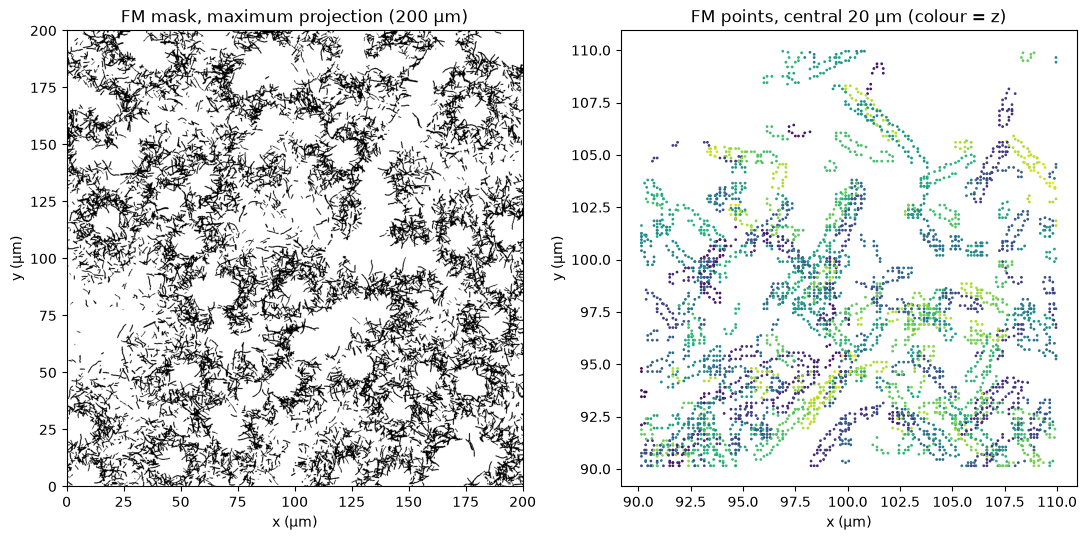

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(fm_mask.max(axis=2).T, origin='lower', cmap='gray_r', extent=(0, FM_FOV_UM, 0, FM_FOV_UM))
axes[0].set_title('FM mask, maximum projection (200 µm)')
zoom = (FM_FOV_UM / 2 - 10, FM_FOV_UM / 2 + 10)
sel = np.all((fm_pts[:, :2] > zoom[0]) & (fm_pts[:, :2] < zoom[1]), axis=1)
axes[1].scatter(fm_pts[sel, 0], fm_pts[sel, 1], s=1, c=fm_pts[sel, 2], cmap='viridis')
axes[1].set_aspect('equal')
axes[1].set_title('FM points, central 20 µm (colour = z)')
for ax in axes:
    ax.set_xlabel('x (µm)')
    ax.set_ylabel('y (µm)')
plt.tight_layout()
plt.show()

## EM volumes with a known transform

An EM volume is a box `fov × fov × EM_DEPTH_UM` in its own coordinates *y*, centred on the origin. Its true pose in FM coordinates is

*x* = *R* · *F* · *y* + *c*

where *R* is a rotation, *F* is either the identity or a z mirror, and *c* is the box centre. The EM mask is rendered from the same tubes at `EM_VOXEL_UM`, without blur, and sampled in the same way as FM.

In [6]:
FLIP = np.diag([1.0, 1.0, -1.0])


def to_homogeneous(rot, trans):
    T = np.eye(4)
    T[:3, :3] = rot
    T[:3, 3] = trans
    return T


def apply(T, pts):
    return pts @ T[:3, :3].T + T[:3, 3]


def random_pose(scenario, rng):
    if scenario in ('planar', 'rotated'):
        rot_z = Rotation.from_euler('z', rng.uniform(0, 360), degrees=True)
        axis = np.array([*rng.normal(size=2), 0.0])
        tilt = Rotation.from_rotvec(axis / np.linalg.norm(axis) * np.deg2rad(rng.uniform(0, 5)))
        rot = (tilt * rot_z).as_matrix()
    else:
        rot = Rotation.random(random_state=rng.integers(1 << 31)).as_matrix()
    flip = FLIP if rng.uniform() < 0.5 else np.eye(3)
    return rot @ flip


def make_em(fov, scenario, rng):
    """Return EM points (refinement and feature resolution) and the true EM -> FM transform."""
    half = np.array([fov / 2, fov / 2, EM_DEPTH_UM / 2])
    margin = fov / 2 + PRIOR_ERROR_UM
    for _ in range(50):
        linear = random_pose(scenario, rng)
        centre = np.array([*rng.uniform(margin, FM_FOV_UM - margin, size=2), FM_DEPTH_UM / 2])
        T_true = to_homogeneous(linear, centre)
        # tube points in EM coordinates, keeping only those near the box
        local = (tubes.points - centre) @ linear   # inverse of x = L y + c, as L is orthogonal
        near = np.all(np.abs(local) < half + 0.5, axis=1)
        if near.sum() < 50:
            continue
        shape = tuple(np.ceil(2 * half / EM_VOXEL_UM).astype(int))
        em_mask = render(local[near], tubes.radius[near], shape, -half, EM_VOXEL_UM)
        em_pts = sample_points(em_mask, -half, EM_VOXEL_UM, REFINE_VOXEL_UM)
        if len(em_pts) >= MIN_EM_POINTS:
            if scenario == 'rotated':
                # same content, expressed in a randomly rotated (and possibly mirrored) frame: y' = Q y
                Q = Rotation.random(random_state=rng.integers(1 << 31)).as_matrix()
                Q = Q @ FLIP if rng.uniform() < 0.5 else Q
                em_pts = em_pts @ Q.T
                T_true = T_true @ to_homogeneous(Q.T, np.zeros(3))   # Q is orthogonal, so its inverse is Q.T
            return em_pts, downsample(em_pts, FEATURE_VOXEL_UM), T_true
    raise RuntimeError('could not place an EM volume with enough points')


def pose_error(T_est, T_true, em_pts):
    """RMS distance (µm) between EM points mapped by the estimated and by the true transform,
    and the angle (degrees) between the two linear parts (inf if one is a mirror and the other not)."""
    rms = np.sqrt(np.mean(np.sum((apply(T_est, em_pts) - apply(T_true, em_pts)) ** 2, axis=1)))
    delta = T_est[:3, :3].T @ T_true[:3, :3]
    if np.linalg.det(delta) < 0:
        return rms, np.inf
    return rms, np.rad2deg(np.arccos(np.clip((np.trace(delta) - 1) / 2, -1, 1)))

## Shared pieces: FPFH features, scoring and refinement

FPFH features for the whole FM cloud are computed once and reused. When a method uses the rough position, it takes the subset of FM points (and their features) within reach of the click, so features near the crop edge are not distorted.

Candidates are ranked by **inlier fraction**: the share of EM points with an FM point within `INLIER_UM`. With the EM cloud as the source, this is measured over the small cloud, so it stays meaningful when the FM cloud is much larger.

In [7]:
reg = o3.pipelines.registration


def to_pcd(pts):
    return o3.geometry.PointCloud(o3.utility.Vector3dVector(pts))


def orient_outward(pcd, k=30):
    """Point each normal away from the centroid of its k nearest neighbours.

    open3d's estimate_normals leaves the sign of each normal tied to the cloud's own axes (they lean
    towards +z), and FPFH depends on that sign, so EM and FM descriptors stop matching when the two
    z axes differ. On curved surfaces such as mitochondria, a point's neighbourhood centroid lies
    inside the object, so this gives outward normals in any frame."""
    pts = np.asarray(pcd.points)
    _, nn = cKDTree(pts).query(pts, k=min(k, len(pts)))
    normals = np.asarray(pcd.normals)
    sign = np.sign(np.sum(normals * (pts - pts[nn].mean(axis=1)), axis=1))
    sign[sign == 0] = 1
    pcd.normals = o3.utility.Vector3dVector(normals * sign[:, None])


def fpfh(pts, voxel=FEATURE_VOXEL_UM):
    pcd = to_pcd(pts)
    pcd.estimate_normals(o3.geometry.KDTreeSearchParamHybrid(radius=2 * voxel, max_nn=30))
    if ORIENT_NORMALS:
        orient_outward(pcd)
    feat = reg.compute_fpfh_feature(pcd, o3.geometry.KDTreeSearchParamHybrid(radius=5 * voxel, max_nn=100))
    return pcd, feat


def subset_feature(feat, idx):
    sub = reg.Feature()
    sub.data = np.asarray(feat.data)[:, idx]
    return sub


t0 = time.time()
fm_pcd_coarse, fm_feat = fpfh(fm_pts_coarse)
fm_tree = cKDTree(fm_pts)
fm_pcd = to_pcd(fm_pts)
fm_tree_coarse = cKDTree(fm_pts_coarse)
print(f'FM features: {time.time() - t0:.0f} s')


def inlier_fraction(T, em_pts, tree=fm_tree):
    d, _ = tree.query(apply(T, em_pts), distance_upper_bound=INLIER_UM)
    return np.mean(np.isfinite(d))


def prior_indices(click, fov, pts):
    reach = fov / np.sqrt(2) + PRIOR_ERROR_UM + 2.0
    return np.flatnonzero(np.linalg.norm(pts[:, :2] - click[:2], axis=1) < reach)


def cap(pts, n=CPD_MAX_POINTS, seed=0):
    if len(pts) <= n:
        return pts
    return pts[np.random.default_rng(seed).choice(len(pts), n, replace=False)]


def refine(T, em_pts):
    """Local rigid refinement of a coarse EM -> FM transform."""
    if REFINER == 'icp':
        res = reg.registration_icp(to_pcd(em_pts), fm_pcd, ICP_MAX_DIST_UM, T,
                                   reg.TransformationEstimationPointToPoint(False),
                                   reg.ICPConvergenceCriteria(max_iteration=100))
        return np.asarray(res.transformation)
    # rigid CPD, as clemreg uses, on the FM points inside the EM box under the current estimate
    fm_in_em = apply(np.linalg.inv(T), fm_pts)
    half = np.ptp(em_pts, axis=0) / 2 + 1.0
    centre = (em_pts.max(0) + em_pts.min(0)) / 2
    target = fm_in_em[np.all(np.abs(fm_in_em - centre) < half, axis=1)]
    if len(target) < 20:
        return T
    res = cpd.registration_cpd(cap(em_pts), cap(target), tf_type_name='rigid', w=CPD_W_REFINE,
                               maxiter=CPD_MAXITER, update_scale=False)
    return T @ to_homogeneous(res.transformation.rot, res.transformation.t)

FM features: 2 s


### Refinement: why ICP rather than CPD

Each coarse result is refined locally before scoring. Rigid CPD would match clemreg, but on these clouds it drifts away from the *true* pose, as the next cell shows. The reason is the sampling: points come from 2D Canny edges in each z slice of each volume, so a cloud samples the surfaces that are steep relative to *its own* z axis. When EM z and FM z differ, the two clouds describe different parts of the same objects, and CPD's global Gaussian mixture is pulled by the difference. ICP with a 1 µm cut-off only matches nearby points and stays put. Whether clemreg's own CPD/BCPD step loses accuracy in the same way on real data is worth checking separately.

In [8]:
check = []
for scenario in SCENARIOS:
    em_pts, _, T_true = make_em(EM_FOVS_UM[-1], scenario, rng)
    for REFINER in ('icp', 'cpd'):
        err, rot = pose_error(refine(T_true, em_pts), T_true, em_pts)
        check.append(dict(scenario=scenario, refiner=REFINER, error_um=err, rot_err_deg=rot))
REFINER = 'icp'
pd.DataFrame(check).round(2)

,scenario,refiner,error_um,rot_err_deg
0,planar,icp,0.01,0.04
1,planar,cpd,0.69,1.33
2,rotated,icp,0.01,0.03
3,rotated,cpd,2.81,4.85
4,free,icp,0.04,0.22
5,free,cpd,0.44,10.33


## Coarse methods

Each method takes the EM clouds (and, if it uses one, the rough position) and returns its best EM → FM transform. Mirrors are handled the same way everywhere: try the EM cloud as it is and z-mirrored, and keep the better result, since a rigid fit can never produce a mirror itself.

In [9]:
def ransac(em_coarse, fm_idx=None):
    target = fm_pcd_coarse if fm_idx is None else fm_pcd_coarse.select_by_index(fm_idx)
    target_feat = fm_feat if fm_idx is None else subset_feature(fm_feat, fm_idx)
    best = (-1.0, None)
    for F in (np.eye(3), FLIP):
        src, src_feat = fpfh(em_coarse @ F.T)
        res = reg.registration_ransac_based_on_feature_matching(
            src, target, src_feat, target_feat,
            mutual_filter=True,
            max_correspondence_distance=1.5 * FEATURE_VOXEL_UM,
            estimation_method=reg.TransformationEstimationPointToPoint(False),
            ransac_n=3,
            checkers=[reg.CorrespondenceCheckerBasedOnEdgeLength(0.9),
                      reg.CorrespondenceCheckerBasedOnDistance(1.5 * FEATURE_VOXEL_UM)],
            criteria=reg.RANSACConvergenceCriteria(RANSAC_MAX_ITER, RANSAC_CONFIDENCE))
        T = np.asarray(res.transformation) @ to_homogeneous(F, np.zeros(3))
        score = inlier_fraction(T, em_coarse, fm_tree_coarse)
        if score > best[0]:
            best = (score, T)
    return best[1]


def teaser(em_coarse):
    """TEASER++ on mutual nearest-neighbour FPFH correspondences (only runs if installed)."""
    fm_feat_tree = cKDTree(np.asarray(fm_feat.data).T)
    best = (-1.0, None)
    for F in (np.eye(3), FLIP):
        src_pts = em_coarse @ F.T
        _, src_feat = fpfh(src_pts)
        sf = np.asarray(src_feat.data).T
        _, j = fm_feat_tree.query(sf)
        _, i_back = cKDTree(sf).query(np.asarray(fm_feat.data).T[j])
        mutual = i_back == np.arange(len(sf))
        params = teaserpp_python.RobustRegistrationSolver.Params()
        params.noise_bound = FEATURE_VOXEL_UM
        params.estimate_scaling = False
        params.rotation_estimation_algorithm = teaserpp_python.RobustRegistrationSolver.ROTATION_ESTIMATION_ALGORITHM.GNC_TLS
        solver = teaserpp_python.RobustRegistrationSolver(params)
        solver.solve(src_pts[mutual].T, fm_pts_coarse[j[mutual]].T)
        sol = solver.getSolution()
        T = to_homogeneous(sol.rotation, sol.translation) @ to_homogeneous(F, np.zeros(3))
        score = inlier_fraction(T, em_coarse, fm_tree_coarse)
        if score > best[0]:
            best = (score, T)
    return best[1]


def rasterise(pts, origin, shape):
    hist, _ = np.histogramdd(pts, bins=shape, range=[(o, o + n * TM_VOXEL_UM) for o, n in zip(origin, shape)])
    return ndimage.gaussian_filter(hist.astype(np.float32), 1.0)


fm_tm_origin = np.array([0.0, 0.0, -1.0])
fm_tm_shape = tuple(np.ceil(np.array([FM_FOV_UM, FM_FOV_UM, FM_DEPTH_UM + 2]) / TM_VOXEL_UM).astype(int))
fm_tm = rasterise(fm_pts_coarse, fm_tm_origin, fm_tm_shape).astype(np.float64)
fm_tm_fft = np.fft.rfftn(fm_tm)


def window_sum(vol, shape):
    """Sum of vol over every window of the given shape that fits inside it ('valid' positions)."""
    c = np.pad(vol, [(1, 0)] * 3).cumsum(0).cumsum(1).cumsum(2)
    a, b, d = shape
    return (c[a:, b:, d:] - c[:-a, b:, d:] - c[a:, :-b, d:] - c[a:, b:, :-d]
            + c[:-a, :-b, d:] + c[:-a, b:, :-d] + c[a:, :-b, :-d] - c[:-a, :-b, :-d])


def ncc_maps(t_shape):
    """FM window statistics for normalised cross-correlation with templates of one shape."""
    n = np.prod(t_shape)
    s1 = window_sum(fm_tm, t_shape)
    s2 = window_sum(fm_tm ** 2, t_shape)
    return n, s1, np.sqrt(np.maximum(s2 - s1 ** 2 / n, 1e-12))


def ncc(tmpl, stats):
    """Normalised cross-correlation of a template with the FM density at every valid offset,
    as skimage.feature.match_template, but reusing the FM spectrum and window sums."""
    n, s1, fm_norm = stats
    t = tmpl - tmpl.mean()
    t_norm = np.sqrt((t ** 2).sum())
    if t_norm == 0:
        return np.full(s1.shape, -np.inf)
    corr = np.fft.irfftn(fm_tm_fft * np.conj(np.fft.rfftn(t, s=fm_tm_shape)), s=fm_tm_shape)
    valid = corr[:s1.shape[0], :s1.shape[1], :s1.shape[2]]
    return valid / (fm_norm * t_norm)


def template_match(em_coarse, fov, click):
    """Normalised cross-correlation of the EM density (a disc of the EM field, so the template covers
    the same area at every angle) against the FM density, over in-plane rotations and a z mirror.
    Returns the best transform without and with the rough position (one NCC map serves both)."""
    disc = em_coarse[np.linalg.norm(em_coarse[:, :2], axis=1) < fov / 2]   # EM frame is centred on the box
    t_shape = np.ceil(np.array([fov, fov, EM_DEPTH_UM + 2]) / TM_VOXEL_UM).astype(int)
    t_shape[2] = min(t_shape[2], fm_tm_shape[2])
    t_half = t_shape * TM_VOXEL_UM / 2
    stats = ncc_maps(tuple(t_shape))
    # FM position of the template's centre for each NCC map entry
    offsets = np.indices(stats[1].shape).reshape(3, -1).T
    centres = fm_tm_origin + offsets * TM_VOXEL_UM + t_half
    near_click = np.flatnonzero(np.linalg.norm(centres[:, :2] - click[:2], axis=1) < PRIOR_ERROR_UM + 2.0)
    best = {'global': (-np.inf, None), 'prior': (-np.inf, None)}
    for F in (np.eye(3), FLIP):
        for angle in np.arange(0, 360, TM_ANGLE_STEP_DEG):
            R = Rotation.from_euler('z', angle, degrees=True).as_matrix() @ F
            score = ncc(rasterise(disc @ R.T, -t_half, tuple(t_shape)), stats).ravel()
            for key, k in (('global', np.argmax(score)), ('prior', near_click[np.argmax(score[near_click])])):
                if score[k] > best[key][0]:
                    best[key] = (score[k], to_homogeneous(R, centres[k]))
    return best['global'][1], best['prior'][1]


def multistart_cpd(em_coarse, click, fov, scenario):
    """Rigid CPD from orthogonal starting orientations (with and without a mirror), centred on the click.

    #73 proposed this for fields of view that mostly overlap. Here the FM crop around the click is many
    times the EM field's area, which is outside that design: the test is whether it still works."""
    idx = prior_indices(click, fov, fm_pts_coarse)
    target = cap(fm_pts_coarse[idx], CPD_MAX_POINTS)
    source = cap(em_coarse, CPD_MAX_POINTS // 4)
    if scenario == 'planar':
        starts = [Rotation.from_euler('z', a, degrees=True).as_matrix() for a in (0, 90, 180, 270)]
    else:
        starts = list(Rotation.create_group('O').as_matrix())   # the 24 rotations of a cube
    best = (-1.0, None)
    for F in (np.eye(3), FLIP):
        for R in starts:
            T0 = to_homogeneous(R @ F, click) @ to_homogeneous(np.eye(3), -em_coarse.mean(0))
            res = cpd.registration_cpd(apply(T0, source), target, tf_type_name='rigid', w=CPD_W_MULTISTART,
                                       maxiter=MULTISTART_MAXITER, update_scale=False)
            T = to_homogeneous(res.transformation.rot, res.transformation.t) @ T0
            score = inlier_fraction(T, em_coarse, fm_tree_coarse)
            if score > best[0]:
                best = (score, T)
    return best[1]

## Run the sweep

In [10]:
def run_trial(scenario, fov, trial):
    em_pts, em_coarse, T_true = make_em(fov, scenario, rng)
    click = T_true[:3, 3] + np.array([*rng.uniform(-1, 1, size=2) * PRIOR_ERROR_UM / np.sqrt(2), 0.0])
    rows = []

    def record(method, fn):
        t0 = time.time()
        T = fn()
        coarse_time = time.time() - t0
        if T is None:
            return
        coarse_err, coarse_rot = pose_error(T, T_true, em_pts)
        T_ref = refine(T, em_pts)
        err, rot = pose_error(T_ref, T_true, em_pts)
        rows.append(dict(scenario=scenario, fov_um=fov, trial=trial, method=method, n_em=len(em_pts),
                         coarse_error_um=coarse_err, coarse_rot_deg=coarse_rot,
                         error_um=err, rot_err_deg=rot, inliers=inlier_fraction(T_ref, em_pts),
                         time_s=coarse_time, success=err < SUCCESS_UM,
                         flip_true=np.linalg.det(T_true[:3, :3]) < 0, T=T_ref))

    fm_idx = prior_indices(click, fov, fm_pts_coarse)
    record('RANSAC', lambda: ransac(em_coarse))
    record('RANSAC + rough position', lambda: ransac(em_coarse, fm_idx))
    if scenario == 'planar':
        tm = {}
        record('Template matching', lambda: tm.setdefault('r', template_match(em_coarse, fov, click))[0])
        record('Template matching + rough position', lambda: tm['r'][1])
        rows[-1]['time_s'] = rows[-2]['time_s']   # both come from the same NCC maps
    record('Multi-start CPD + rough position', lambda: multistart_cpd(em_coarse, click, fov, scenario))
    if teaserpp_python is not None:
        record('TEASER++', lambda: teaser(em_coarse))
    return rows, (em_pts, T_true, click)


results, examples = [], {}
t_start = time.time()
for scenario in SCENARIOS:
    for fov in EM_FOVS_UM:
        for trial in range(N_TRIALS):
            rows, example = run_trial(scenario, fov, trial)
            results.extend(rows)
            examples[(scenario, fov, trial)] = example
            print(f'{scenario:6s} {fov:4.0f} µm trial {trial}: '
                  + ', '.join(f"{r['method']} {r['error_um']:.1f}" for r in rows)
                  + f'  ({time.time() - t_start:.0f} s total)')

df = pd.DataFrame(results)

planar   10 µm trial 0: RANSAC 108.8, RANSAC + rough position 0.0, Template matching 0.0, Template matching + rough position 0.0, Multi-start CPD + rough position 10.7  (17 s total)


planar   10 µm trial 1: RANSAC 179.8, RANSAC + rough position 8.5, Template matching 0.1, Template matching + rough position 0.1, Multi-start CPD + rough position 8.1  (34 s total)


planar   10 µm trial 2: RANSAC 14.9, RANSAC + rough position 14.9, Template matching 122.3, Template matching + rough position 0.1, Multi-start CPD + rough position 11.0  (49 s total)


planar   10 µm trial 3: RANSAC 104.0, RANSAC + rough position 18.6, Template matching 0.1, Template matching + rough position 0.1, Multi-start CPD + rough position 16.7  (63 s total)


planar   10 µm trial 4: RANSAC 86.2, RANSAC + rough position 14.9, Template matching 94.2, Template matching + rough position 0.1, Multi-start CPD + rough position 12.7  (76 s total)


...

free     50 µm trial 3: RANSAC 39.3, RANSAC + rough position 37.0, Multi-start CPD + rough position 29.2  (1768 s total)


free     50 µm trial 4: RANSAC 116.3, RANSAC + rough position 43.7, Multi-start CPD + rough position 19.1  (1799 s total)


free     50 µm trial 5: RANSAC 60.2, RANSAC + rough position 34.9, Multi-start CPD + rough position 24.3  (1828 s total)


free     50 µm trial 6: RANSAC 110.0, RANSAC + rough position 0.0, Multi-start CPD + rough position 26.0  (1863 s total)


free     50 µm trial 7: RANSAC 93.5, RANSAC + rough position 0.1, Multi-start CPD + rough position 30.4  (1888 s total)


## Results

Success means the final error (after the ICP refinement) is below `SUCCESS_UM`. The error is the RMS distance between the EM points placed by the estimated and by the true transform.

In [11]:
METHOD_ORDER = ['RANSAC', 'RANSAC + rough position', 'Template matching',
                'Template matching + rough position', 'Multi-start CPD + rough position', 'TEASER++']
COLOURS = dict(zip(METHOD_ORDER, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']))
MARKERS = dict(zip(METHOD_ORDER, ['o', 's', '^', 'D', 'v', 'P']))
methods = [m for m in METHOD_ORDER if m in set(df.method)]

summary = (df.assign(coarse_ok=df.coarse_error_um < COARSE_SUCCESS_UM)
             .groupby(['scenario', 'fov_um', 'method'])
             .agg(trials=('success', 'size'), median_n_em=('n_em', 'median'),
                  coarse_ok=('coarse_ok', 'mean'), success=('success', 'mean'),
                  median_error_um=('error_um', 'median'), median_time_s=('time_s', 'median'))
             .reset_index())
summary['method'] = pd.Categorical(summary.method, methods, ordered=True)
summary['scenario'] = pd.Categorical(summary.scenario, SCENARIOS, ordered=True)
summary = summary.sort_values(['scenario', 'fov_um', 'method'])
summary.style.format({'coarse_ok': '{:.0%}', 'success': '{:.0%}', 'median_error_um': '{:.2f}',
                      'median_time_s': '{:.1f}'}).hide(axis='index')

scenario,fov_um,method,trials,median_n_em,coarse_ok,success,median_error_um,median_time_s
planar,10.000000,RANSAC,8,1052.000000,0%,0%,106.41,1.7
planar,10.000000,RANSAC + rough position,8,1052.000000,38%,38%,10.21,0.3
planar,10.000000,Template matching,8,1052.000000,75%,75%,0.05,10.5
planar,10.000000,Template matching + rough position,8,1052.000000,100%,100%,0.05,10.5
planar,10.000000,Multi-start CPD + rough position,8,1052.000000,0%,0%,12.84,2.3
planar,20.000000,RANSAC,8,6383.500000,0%,0%,97.22,2.6
planar,20.000000,RANSAC + rough position,8,6383.500000,88%,88%,0.03,1.0
planar,20.000000,Template matching,8,6383.500000,100%,100%,0.02,10.7
planar,20.000000,Template matching + rough position,8,6383.500000,100%,100%,0.02,10.7
planar,20.000000,Multi-start CPD + rough position,8,6383.500000,12%,12%,15.92,3.1


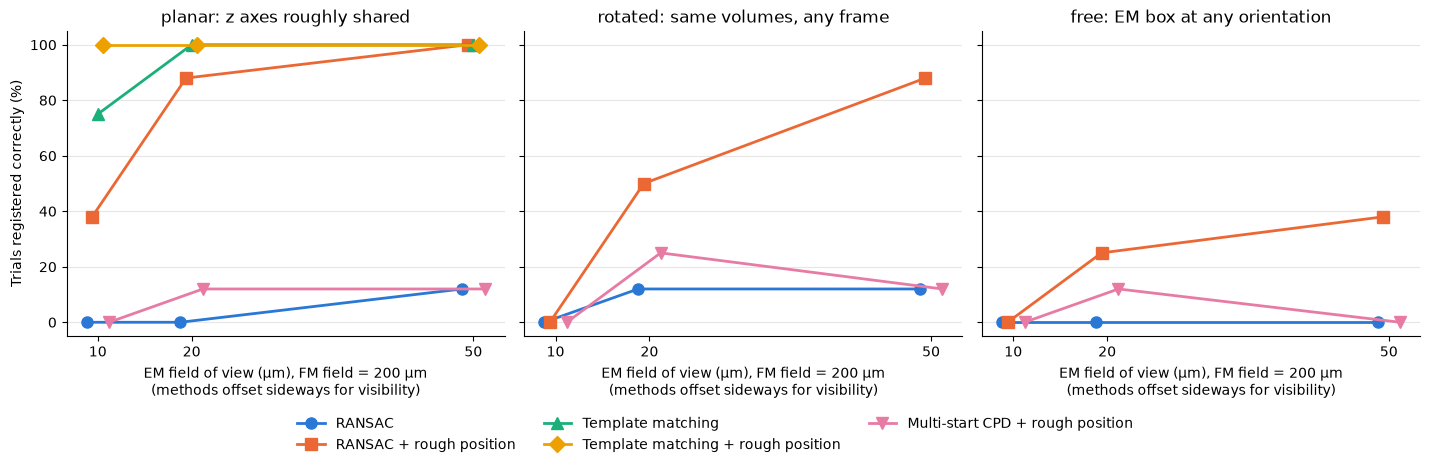

In [12]:
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(4.8 * len(SCENARIOS), 4.2), sharey=True, squeeze=False)
for ax, scenario in zip(axes[0], SCENARIOS):
    sub = summary[summary.scenario == scenario]
    for i, m in enumerate(methods):
        line = sub[sub.method == m]
        if len(line):
            # offset each method slightly sideways so overlapping lines stay visible
            dodge = (i - (len(methods) - 1) / 2) * 0.6
            ax.plot(line.fov_um + dodge, line.success * 100, marker=MARKERS[m], markersize=8, lw=2,
                    color=COLOURS[m], label=m)
    ax.set_title({'planar': 'planar: z axes roughly shared', 'rotated': 'rotated: same volumes, any frame',
                  'free': 'free: EM box at any orientation'}[scenario])
    ax.set_xlabel(f'EM field of view (µm), FM field = {FM_FOV_UM:.0f} µm\n(methods offset sideways for visibility)')
    ax.set_xticks(EM_FOVS_UM)
    ax.set_ylim(-5, 105)
    ax.grid(axis='y', color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].set_ylabel('Trials registered correctly (%)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

### One trial, seen from above

The true EM footprint (black) and each method's final estimate, on the FM points around it. A correct method's outline sits on the black one.

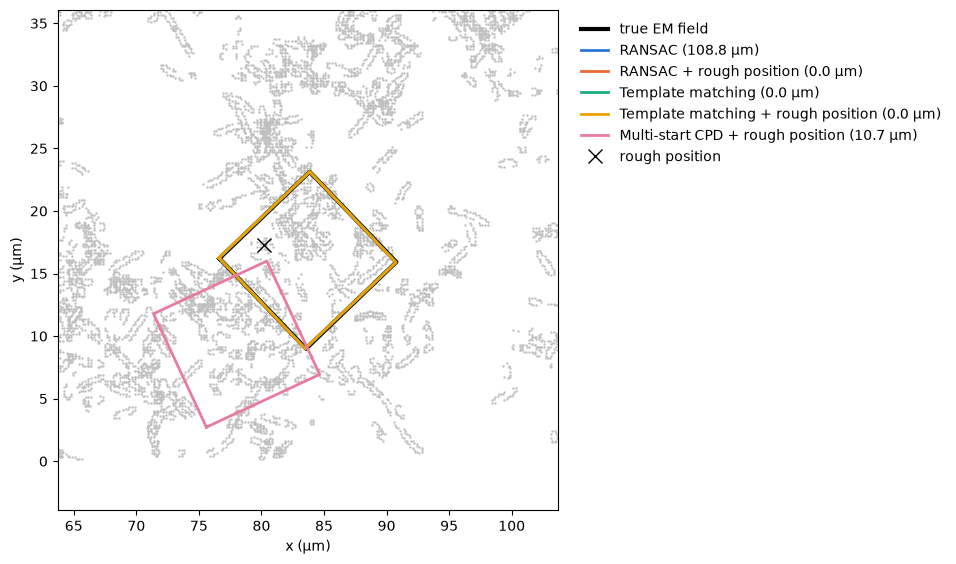

In [13]:
def footprint(T, fov):
    h = fov / 2
    corners = np.array([[-h, -h, 0], [h, -h, 0], [h, h, 0], [-h, h, 0], [-h, -h, 0]])
    return apply(T, corners)


key = ('planar', EM_FOVS_UM[0], 0)
em_pts, T_true, click = examples[key]
fov = key[1]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
view = 3 * fov + PRIOR_ERROR_UM
near = np.all(np.abs(fm_pts[:, :2] - T_true[:2, 3]) < view / 2, axis=1)
ax.scatter(fm_pts[near, 0], fm_pts[near, 1], s=0.5, c='0.75')
fp = footprint(T_true, fov)
ax.plot(fp[:, 0], fp[:, 1], color='black', lw=3, label='true EM field')
for _, r in df[(df.scenario == key[0]) & (df.fov_um == key[1]) & (df.trial == key[2])].iterrows():
    fp = footprint(r['T'], fov)
    ax.plot(fp[:, 0], fp[:, 1], color=COLOURS[r['method']], lw=2,
            label=f"{r['method']} ({r['error_um']:.1f} µm)")
ax.plot(*click[:2], marker='x', color='black', markersize=10, ls='none', label='rough position')
ax.set_xlim(T_true[0, 3] - view / 2, T_true[0, 3] + view / 2)
ax.set_ylim(T_true[1, 3] - view / 2, T_true[1, 3] + view / 2)
ax.set_aspect('equal')
ax.set_xlabel('x (µm)')
ax.set_ylabel('y (µm)')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.show()

## Findings

From the saved full run (8 trials per cell, so each percentage is uncertain by roughly ±15–30 points). All of this is synthetic; see the caveats at the top.

1. **RANSAC alone can't find a small EM field in 200 µm of FM.** Without a rough position it succeeded in 0–12% of trials at every EM field size and in every scenario. The field-of-view mismatch, not orientation, is what stops it.
2. **A rough position makes RANSAC usable, but only for larger EM fields.** With the click (±10 µm), `planar` trials succeeded 38% / 88% / 100% at 10 / 20 / 50 µm, in about 1–2 s each.
3. **Template matching is the strongest coarse method when the z axes roughly agree.** Over in-plane rotations and a mirror, it found the EM field in 75–100% of `planar` trials *without* a rough position, and in 100% with one, including the 10 µm fields, in about 11 s per trial.
4. **RANSAC doesn't fully remove the orientation problem.** In `rotated` (the same EM volumes as `planar`, in a randomly rotated frame), RANSAC with a rough position succeeded 0% / 50% / 88%, against 38% / 88% / 100% for `planar`. That is better than before the normal-orientation fix (`orient_outward`; 0% / 38% / 50%), but still behind. At 50 µm it mostly handles any orientation; for EM fields of 10–20 µm, orientation still costs a lot.
5. **`free` is harder still, partly because there is less to match.** A thin EM slab tipped across the cell layer held a median of 6k points against 36k for `planar` at 50 µm. RANSAC with a rough position reached 0–38%.
6. **Multi-start CPD isn't a fallback for very different fields of view.** It succeeded in 0–25% of trials, and in development runs it also failed with an exact click. Its Gaussian mixture is drawn to FM points around the EM field. This doesn't test it on overlapping fields of view, which is what #73 proposed it for.
7. **Mirrors:** the table below shows no clear difference between mirrored and unmirrored trials, given the small numbers.

**Side findings worth checking in clemreg itself:**

- open3d's `estimate_normals` leaves normal signs leaning towards the cloud's own +z. FPFH depends on those signs, so EM and FM descriptors disagree when the z axes differ (see `orient_outward`).
- Started from the true pose, rigid CPD drifted by 0.4–2.8 µm and up to 10° on these clouds, while ICP stayed within 0.04 µm (see *Refinement*). clemreg registers with CPD/BCPD, so it's worth checking whether this happens on real data.

**So, does global registration also solve the 3D orientation problem?** Partly. When EM and FM share roughly the same z axis, template matching over in-plane rotations and a mirror solves both the position and the in-plane orientation, even for 10 µm fields. For arbitrary 3D orientations, RANSAC with a rough position works for EM fields of about 50 µm, but not reliably for smaller ones.

In [14]:
(df.groupby(['scenario', 'flip_true', 'method'])['success'].mean().unstack('method')
   .reindex(columns=methods).style.format('{:.0%}', na_rep='–'))

## Next steps

- **Template matching over 3D orientations.** Run the template matcher once for each of the 6 choices of which EM axis maps to FM z (×2 for the mirror is already covered), with in-plane angles as now. That would extend finding 3 to the `rotated` case at about 6× the cost, and could be the answer to #73 for small EM fields.
- **Real data.** Repeat with real FM/EM pairs: cut sub-volumes out of the sample EM mask (`napari_clemreg/clemreg/data/em_mask.tif`) and register them to the sample FM segmentation, and if possible a large-FOV FM dataset with a small FIB-SEM volume.
- **Parameter sensitivity.** `FEATURE_VOXEL_UM` (the FPFH radius is 5× this), the mutual filter, `TM_ANGLE_STEP_DEG`, and mitochondrial density (sparser fields give fewer, possibly more distinctive features).
- **The sampling itself.** Per-slice 2D Canny makes a cloud depend on its volume's z axis (see *Refinement*). 3D edge or surface sampling, or the samplers proposed in #75, would make EM and FM clouds more alike when their z axes differ, which should help every method here.
- **Masked NCC.** The template matcher scores the empty corners of the template's box as "no mitochondria". Masked normalised cross-correlation (Padfield 2012) would remove that bias.
- **TEASER++.** Not on PyPI; build it from source to include it in the comparison.
- **Where it would live.** A coarse step fits in the core's `register_point_clouds` after package split phase 1 (#58), as an optional initialiser before CPD/BCPD, with the rough position as an optional napari Points input.